In [1]:
!pip install deap scikit-learn pandas numpy matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score, KFold
from deap import base, creator, tools, algorithms


In [3]:
# -------------------------------------------------------------------
# Paso 1: Configuración de Semillas y Carga de Datos
# -------------------------------------------------------------------

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

wine = load_wine()
X, y = wine.data, wine.target
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Rendimiento base por defecto
default_clf = AdaBoostClassifier(random_state=RANDOM_SEED)
default_acc = cross_val_score(default_clf, X, y, cv=kfold, scoring='accuracy').mean()
print(f"Precisión media con hiperparámetros por defecto: {default_acc:.4f}")

Precisión media con hiperparámetros por defecto: 0.9495


In [4]:
# -------------------------------------------------------------------
# Paso 2: Conversión del cromosoma a hiperparámetros reales
# -------------------------------------------------------------------
# [n_estimators (1..100), learning_rate (0.01..1.0), max_depth (1..5)]
BOUNDS_LOW  = [1.0,   0.01, 1.0]
BOUNDS_HIGH = [100.0, 1.00, 5.0]
NUM_PARAMS = len(BOUNDS_LOW)

from sklearn.tree import DecisionTreeClassifier

def convert_params(params):
    n_estimators  = int(round(params[0]))
    learning_rate = float(params[1])
    max_depth     = int(round(params[2]))
    max_depth     = max(1, min(5, max_depth))
    return n_estimators, learning_rate, max_depth

def evaluate_hyperparameters(individual):
    n_est, lr, depth = convert_params(individual)
    clf = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_SEED),
        n_estimators=n_est,
        learning_rate=lr,
        random_state=RANDOM_SEED
    )
    scores = cross_val_score(clf, X, y, cv=kfold, scoring='accuracy')
    return (scores.mean(),)

In [5]:
# -------------------------------------------------------------------
# Paso 3: Configuración del AG con DEAP
# -------------------------------------------------------------------
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()

def create_individual():
    return creator.Individual(
        random.uniform(BOUNDS_LOW[i], BOUNDS_HIGH[i]) for i in range(NUM_PARAMS)
    )

toolbox.register("individualCreator", create_individual)
toolbox.register("populationCreator", tools.initRepeat, list, toolbox.individualCreator)

toolbox.register("evaluate", evaluate_hyperparameters)
toolbox.register("select", tools.selTournament, tournsize=2)
toolbox.register("mate", tools.cxSimulatedBinaryBounded,
                 low=BOUNDS_LOW, up=BOUNDS_HIGH, eta=20.0)
toolbox.register("mutate", tools.mutPolynomialBounded,
                 low=BOUNDS_LOW, up=BOUNDS_HIGH, eta=20.0, indpb=1.0/NUM_PARAMS)

In [6]:
# -------------------------------------------------------------------
# Paso 4: Búsqueda evolutiva
# -------------------------------------------------------------------
POPULATION_SIZE = 20
MAX_GENERATIONS = 5
P_CROSSOVER = 0.9
P_MUTATION = 0.1

population = toolbox.populationCreator(n=POPULATION_SIZE)
hof = tools.HallOfFame(3)

stats = tools.Statistics(lambda ind: ind.fitness.values)
stats.register("max", np.max)
stats.register("avg", np.mean)

population, logbook = algorithms.eaSimple(
    population, toolbox, cxpb=P_CROSSOVER, mutpb=P_MUTATION,
    ngen=MAX_GENERATIONS, stats=stats, halloffame=hof, verbose=True
)

gen	nevals	max     	avg     
0  	20    	0.971905	0.942452
1  	20    	0.977619	0.96104 
2  	18    	0.977619	0.966087
3  	19    	0.977619	0.970056
4  	20    	0.977619	0.970889
5  	19    	0.972063	0.969492



RESULTADO FINAL DE LA OPTIMIZACIÓN:
- n_estimators optimizado: 72
- learning_rate optimizado: 0.6419
- max_depth del árbol base: 2
- Precisión lograda: 0.9776
- Precisión base inicial: 0.9495


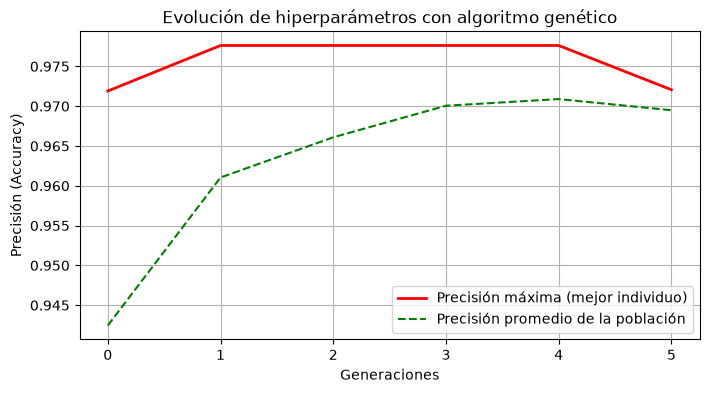

In [7]:
# -------------------------------------------------------------------
# Paso 5: Resultados y gráfica
# -------------------------------------------------------------------
best_ind = hof[0]
best_n_est, best_lr, best_depth = convert_params(best_ind)

print("\n" + "="*50)
print("RESULTADO FINAL DE LA OPTIMIZACIÓN:")
print(f"- n_estimators optimizado: {best_n_est}")
print(f"- learning_rate optimizado: {best_lr:.4f}")
print(f"- max_depth del árbol base: {best_depth}")
print(f"- Precisión lograda: {best_ind.fitness.values[0]:.4f}")
print(f"- Precisión base inicial: {default_acc:.4f}")
print("="*50)

max_scores = logbook.select("max")
avg_scores = logbook.select("avg")

plt.figure(figsize=(8, 4))
plt.plot(max_scores, label="Precisión máxima (mejor individuo)", color="red", linewidth=2)
plt.plot(avg_scores, label="Precisión promedio de la población", color="green", linestyle="--")
plt.xlabel("Generaciones")
plt.ylabel("Precisión (Accuracy)")
plt.title("Evolución de hiperparámetros con algoritmo genético")
plt.legend()
plt.grid(True)
plt.show()